In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#import mglearn
from cycler import cycler

import warnings
warnings.filterwarnings('ignore') 

In [8]:
import pandas as pd

df = pd.read_csv(r"C:\Users\thais\Documents\Springboard\Machine_Learning_\CA1\Eletric Vehicle Population.csv")

In [9]:
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,3FMTK3SU8P,King,Seattle,WA,98177.0,2023,FORD,MUSTANG MACH-E,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,32.0,254622924,POINT (-122.37238 47.74068),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10
1,JM3KKEHA8S,Thurston,Yelm,WA,98597.0,2025,MAZDA,CX-90,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,26.0,2.0,277791643,POINT (-122.60735 46.94239),PUGET SOUND ENERGY INC,5.306701e+10
2,5YJ3E1EB8J,King,Sammamish,WA,98075.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,41.0,347418676,POINT (-122.03539 47.61344),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10
3,JHMZC5F12K,Island,Oak Harbor,WA,98277.0,2019,HONDA,CLARITY,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,47.0,10.0,223620701,POINT (-122.64682 48.29077),PUGET SOUND ENERGY INC,5.302997e+10
4,1C4RJXN65R,Kitsap,Bremerton,WA,98312.0,2024,JEEP,WRANGLER,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,21.0,26.0,256402674,POINT (-122.65223 47.57192),PUGET SOUND ENERGY INC,5.303508e+10


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300142 entries, 0 to 300141
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         300142 non-null  object 
 1   County                                             300127 non-null  object 
 2   City                                               300127 non-null  object 
 3   State                                              300142 non-null  object 
 4   Postal Code                                        300127 non-null  float64
 5   Model Year                                         300142 non-null  int64  
 6   Make                                               300142 non-null  object 
 7   Model                                              300142 non-null  object 
 8   Electric Vehicle Type                              300142 non-null  object

In [11]:
df.isnull().sum()

VIN (1-10)                                             0
County                                                15
City                                                  15
State                                                  0
Postal Code                                           15
Model Year                                             0
Make                                                   0
Model                                                  0
Electric Vehicle Type                                  0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Range                                        35
Legislative District                                 790
DOL Vehicle ID                                         0
Vehicle Location                                      24
Electric Utility                                      15
2020 GEOID                                            15
dtype: int64

In [12]:
df.duplicated().sum()

0

In [13]:
df.shape

(300142, 16)

In [14]:
df["Electric Vehicle Type"].value_counts()

Battery Electric Vehicle (BEV)            241840
Plug-in Hybrid Electric Vehicle (PHEV)     58302
Name: Electric Vehicle Type, dtype: int64

In [15]:
df.describe()

,Postal Code,Model Year,Electric Range,Legislative District,DOL Vehicle ID,2020 GEOID
count,300127.000000,300142.000000,300107.000000,299352.000000,3.001420e+05,3.001270e+05
mean,98175.788819,2022.389056,36.148437,28.719230,2.516250e+08,5.296688e+10
std,2669.566595,3.095011,75.443498,14.886897,6.211185e+07,1.696036e+09
min,1030.000000,1999.000000,0.000000,1.000000,4.385000e+03,1.001020e+09
25%,98052.000000,2021.000000,0.000000,17.000000,2.287301e+08,5.303301e+10
50%,98134.000000,2023.000000,0.000000,32.000000,2.686437e+08,5.303303e+10
75%,98391.000000,2025.000000,32.000000,42.000000,2.851263e+08,5.305394e+10
max,99403.000000,2027.000000,337.000000,49.000000,4.791150e+08,6.601095e+10


In [16]:
df = df.dropna()

In [17]:
df.shape

(299308, 16)

In [18]:
df["Electric Vehicle Type"].value_counts()

Battery Electric Vehicle (BEV)            241231
Plug-in Hybrid Electric Vehicle (PHEV)     58077
Name: Electric Vehicle Type, dtype: int64

In [19]:
df.columns

Index(['VIN (1-10)', 'County', 'City', 'State', 'Postal Code', 'Model Year',
       'Make', 'Model', 'Electric Vehicle Type',
       'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range',
       'Legislative District', 'DOL Vehicle ID', 'Vehicle Location',
       'Electric Utility', '2020 GEOID'],
      dtype='object')

In [20]:
df = df.drop(columns=[
    'VIN (1-10)',
    'DOL Vehicle ID',
    'Vehicle Location',
    '2020 GEOID',
    'State',
    
   ])

In [21]:
df.columns

Index(['County', 'City', 'Postal Code', 'Model Year', 'Make', 'Model',
       'Electric Vehicle Type',
       'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range',
       'Legislative District', 'Electric Utility'],
      dtype='object')

In [22]:
df.isnull().sum().sort_values(ascending=False)

County                                               0
City                                                 0
Postal Code                                          0
Model Year                                           0
Make                                                 0
Model                                                0
Electric Vehicle Type                                0
Clean Alternative Fuel Vehicle (CAFV) Eligibility    0
Electric Range                                       0
Legislative District                                 0
Electric Utility                                     0
dtype: int64

In [23]:
y = df["Electric Vehicle Type"]
X = df.drop("Electric Vehicle Type", axis=1)

In [24]:
X.head()

,County,City,Postal Code,Model Year,Make,Model,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility
0,King,Seattle,98177.0,2023,FORD,MUSTANG MACH-E,Eligibility unknown as battery range has not b...,0.0,32.0,CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA)
1,Thurston,Yelm,98597.0,2025,MAZDA,CX-90,Not eligible due to low battery range,26.0,2.0,PUGET SOUND ENERGY INC
2,King,Sammamish,98075.0,2018,TESLA,MODEL 3,Clean Alternative Fuel Vehicle Eligible,215.0,41.0,PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)
3,Island,Oak Harbor,98277.0,2019,HONDA,CLARITY,Clean Alternative Fuel Vehicle Eligible,47.0,10.0,PUGET SOUND ENERGY INC
4,Kitsap,Bremerton,98312.0,2024,JEEP,WRANGLER,Not eligible due to low battery range,21.0,26.0,PUGET SOUND ENERGY INC


In [25]:
y.value_counts()

Battery Electric Vehicle (BEV)            241231
Plug-in Hybrid Electric Vehicle (PHEV)     58077
Name: Electric Vehicle Type, dtype: int64

In [26]:
X = pd.get_dummies(X, drop_first = True)

In [27]:
X.shape

(299308, 880)

In [28]:
y = y.map({
     'Battery Electric Vehicle (BEV)':0,
     'Plug-in Hybrid Electric Vehicle (PHEV)': 1
      
})

In [80]:
y.head()

0    0
1    1
2    0
3    1
4    1
Name: Electric Vehicle Type, dtype: int64

In [29]:
X.head()

,Postal Code,Model Year,Electric Range,Legislative District,County_Asotin,County_Benton,County_Chelan,County_Clallam,County_Clark,County_Columbia,...,Electric Utility_PORTLAND GENERAL ELECTRIC CO,Electric Utility_PUD NO 1 OF CHELAN COUNTY,Electric Utility_PUD NO 1 OF DOUGLAS COUNTY,Electric Utility_PUD NO 1 OF OKANOGAN COUNTY,Electric Utility_PUD NO 1 OF PEND OREILLE COUNTY,Electric Utility_PUD NO 1 OF WHATCOM COUNTY,Electric Utility_PUD NO 2 OF GRANT COUNTY,Electric Utility_PUGET SOUND ENERGY INC,Electric Utility_PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),Electric Utility_PUGET SOUND ENERGY INC||PUD NO 1 OF WHATCOM COUNTY
0,98177.0,2023,0.0,32.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,98597.0,2025,26.0,2.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,98075.0,2018,215.0,41.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,98277.0,2019,47.0,10.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,98312.0,2024,21.0,26.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [31]:
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

modelo = DecisionTreeClassifier(random_state=42)

modelo.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [39]:
y_pred = modelo.predict(X_test)

In [38]:
from sklearn import metrics

print("accuracy:", metrics.accuracy_score(y_test, y_pred))

print("precision:", metrics.precision_score(y_test, y_pred))

print("recall:", metrics.recall_score(y_test, y_pred))         

accuracy: 1.0
precision: 1.0
recall: 1.0


In [40]:
X.columns

Index(['Postal Code', 'Model Year', 'Electric Range', 'Legislative District',
       'County_Asotin', 'County_Benton', 'County_Chelan', 'County_Clallam',
       'County_Clark', 'County_Columbia',
       ...
       'Electric Utility_PORTLAND GENERAL ELECTRIC CO',
       'Electric Utility_PUD NO 1 OF CHELAN COUNTY',
       'Electric Utility_PUD NO 1 OF DOUGLAS COUNTY',
       'Electric Utility_PUD NO 1 OF OKANOGAN COUNTY',
       'Electric Utility_PUD NO 1 OF PEND OREILLE COUNTY',
       'Electric Utility_PUD NO 1 OF WHATCOM COUNTY',
       'Electric Utility_PUD NO 2 OF GRANT COUNTY',
       'Electric Utility_PUGET SOUND ENERGY INC',
       'Electric Utility_PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)',
       'Electric Utility_PUGET SOUND ENERGY INC||PUD NO 1 OF WHATCOM COUNTY'],
      dtype='object', length=880)

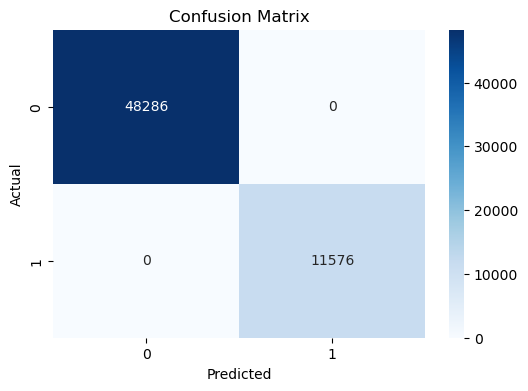

In [47]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [50]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     48286
           1       1.00      1.00      1.00     11576

    accuracy                           1.00     59862
   macro avg       1.00      1.00      1.00     59862
weighted avg       1.00      1.00      1.00     59862

